# Data Import

In [1]:
import torch

In [2]:
torch.cuda.is_available()

True

In [3]:
device= 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [4]:
!pip install pypdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 407.8/407.8 kB 29.1 MB/s eta 0:00:00


In [5]:
import torch
from torch.nn import functional as F
import torch.nn as nn
import matplotlib.pyplot as plt

In [6]:
import os

pdf_path = "/content/harrypotter_books.pdf"

print("Exists:", os.path.exists(pdf_path))

if os.path.exists(pdf_path):
    print("Size (MB):", round(os.path.getsize(pdf_path) / (1024 * 1024), 2))

    with open(pdf_path, "rb") as f:
        header = f.read(10)
        f.seek(max(0, os.path.getsize(pdf_path) - 100))
        ending = f.read()

    print("Header:", header)
    print("Contains EOF marker:", b"%%EOF" in ending)

Exists: True
Size (MB): 2.0
Header: b'%PDF-1.4\n%'
Contains EOF marker: False


In [8]:
from pypdf import PdfReader

reader = PdfReader(r"/content/harrypotter_books.pdf")

raw_text = ""

for page in reader.pages:
    page_text = page.extract_text()
    if page_text:
        raw_text += page_text + "\n"

text = raw_text.replace("\t", " ")

print("Extracted characters:", len(text))
print(text[:1000])

Extracted characters: 6635133
CONTENTS
Harry Potter and the Sorcerer’s Stone
Harry Potter and the Chamber of Secrets
Harry Potter and the Prisoner of Azkaban
Harry Potter and the Goblet of Fire
Harry Potter and the Order of the Phoenix
Harry Potter and the Half-Blood Prince
Harry Potter and the Deathly Hallows
 
F
OR
 J
ESSICA
, 
WHO LOVES STORIES
,
FOR
 A
NNE
, 
WHO LOVED THEM TOO
;
AND FOR
 D
I
, 
WHO HEARD THIS ONE FIRST
.
 
CONTENTS
ONE
The Boy Who Lived
TWO
The Vanishing Glass
THREE
The Letters from No One
FOUR
The Keeper of the Keys
FIVE
Diagon Alley
SIX
The Journey from Platform Nine and Three-quarters
SEVEN
The Sorting Hat
EIGHT
The Potions Master
NINE
The Midnight Duel
TEN
Halloween
ELEVEN
Quidditch
TWELVE
The Mirror of Erised
THIRTEEN
Nicolas Flamel
FOURTEEN
Norbert the Norwegian Ridgeback
FIFTEEN
The Forbidden Forest
SIXTEEN
Through the Trapdoor
SEVENTEEN
The Man with Two Faces
M
 
CHAPTER  ONE
THE BOY WHO LIVED
r. and Mrs. Dursley, of number four, Privet Drive, were proud t

In [ ]:
# from pypdf import PdfReader

# dir = '/content/harrypotter_books.pdf'
# reader = PdfReader(dir)

# raw_text = ""

# for page in reader.pages:
#     page_text = page.extract_text()
#     if page_text:
#         raw_text += page_text + "\n"

# text = raw_text.replace('\t', ' ')

# Tokenize using BPE

In [9]:
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import ByteLevel
from tokenizers.decoders import ByteLevel as ByteLevelDecoder

tokenizer = Tokenizer(BPE(unk_token="[UNK]"))

# Split text into byte-level pieces before BPE learns merges
tokenizer.pre_tokenizer = ByteLevel(add_prefix_space=False)

trainer = BpeTrainer(
    vocab_size=8000, # actual size can slightly differ
    min_frequency=2,
    special_tokens=["[UNK]", "[BOS]", "[EOS]", "[PAD]"],
    initial_alphabet=ByteLevel.alphabet()
)

# Learn the vocabulary and merge rules from your book text
tokenizer.train_from_iterator([raw_text], trainer=trainer)

# Configure decoding so token IDs can be converted back into readable text
tokenizer.decoder = ByteLevelDecoder()

print("Vocabulary size:", tokenizer.get_vocab_size())

Vocabulary size: 8000


In [10]:
sample_text= "Hello I am Aaditya Gangurde"

encoded= tokenizer.encode(sample_text)
print(encoded.tokens)
print(encoded.ids)

print()

decoded= tokenizer.decode(encoded.ids) # pass the ids not the tokens
print(decoded)

['Hello', 'ĠI', 'Ġam', 'ĠA', 'ad', 'ity', 'a', 'ĠG', 'ang', 'ur', 'de']
[4543, 436, 1731, 650, 328, 852, 68, 664, 514, 351, 533]

Hello I am Aaditya Gangurde


## Encoding the text

In [11]:
encoded_text_ids= tokenizer.encode(text).ids

In [12]:
# tokenizer.decode(encoded_text_ids[torch.randint])


In [13]:
data= torch.tensor(encoded_text_ids, dtype=torch.long) # converting ids from list to tensor
data.shape

torch.Size([2101923])

In [14]:
data[:5]

tensor([  38, 1910,   55, 2479,   54])

# Train Val split


In [15]:
split_index= 0.85
n= len(data)

In [16]:
train_data= data[:int(n*split_index)]
val_data= data[int(n*split_index):]

In [17]:
print(train_data.shape)
print(val_data.shape)

torch.Size([1786634])
torch.Size([315289])


# Setting hyperparameters

In [49]:
batch_size=32 # no. of seq
block_size=128 # context window

vocab_size = tokenizer.get_vocab_size()

embed_dim = 256       # Vector size used to represent each token
n_heads = 4           # Number of attention heads
n_layers = 4           # Number of Transformer blocks
block_size = 128       # Maximum context length
head_size=embed_dim//n_heads

# Training settings
dropout = 0.1
lr1 = 3e-4 # phase 1 lr
lr2= 1e-4 # phase 2 lr
max_iters1 = 7000 # For Phase 1 training
max_iters2 = 10000 # For Phase 2 training
eval_interval = 250
eval_iters = 20

# Get batch function

In [20]:
def get_batch(split):

    source = train_data if split == "train" else val_data

    # Randomly select starting positions for sequences
    start_positions = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )

    # Inputs: tokens from position i to i + block_size
    x = torch.stack([
        source[i : i + block_size]
        for i in start_positions
    ])

    # Targets: the same sequences shifted one token forward
    y = torch.stack([
        source[i + 1 : i + block_size + 1]
        for i in start_positions
    ])

    return x, y

In [21]:
x,y=get_batch('train')
print(x.shape)
print(y.shape)

torch.Size([32, 128])
torch.Size([32, 128])


In [22]:
tokenizer.decode(x[0][:10].tolist())

' NOT — DEAD!” roared Harry.'

In [23]:
tokenizer.decode(y[0][:10].tolist())

'OT — DEAD!” roared Harry. “'

# Head Class

In [24]:
class Head(nn.Module):
    def __init__(self, embed_dim, head_size, block_size, dropout):
        super().__init__()

        self.key = nn.Linear(embed_dim, head_size, bias=False)
        self.query = nn.Linear(embed_dim, head_size, bias=False)
        self.value = nn.Linear(embed_dim, head_size, bias=False)

        # mask prevents attention to future tokens
        self.register_buffer(
            "mask",
            torch.tril(torch.ones(block_size, block_size))
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape

        # Generate query, key, and value vectors
        k = self.key(x)
        q = self.query(x)
        v = self.value(x)

        # Calculate scaled attention scores
        scores = q @ k.transpose(-2, -1)
        scores = scores * (k.shape[-1] ** -0.5)

        # Prevent each token from looking at future tokens
        scores = scores.masked_fill(
            self.mask[:T, :T] == 0,
            float("-inf")
        )

        # Convert scores into attention probabilities
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        # Weighted combination of value vectors
        out = weights @ v

        return out

# MultiHead Attention Class

In [25]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, n_heads, head_size, block_size, dropout):
        super().__init__()

        # Raise an error if the dimensions are incompatible
        if embed_dim != n_heads * head_size:
            raise ValueError(
                f"embed_dim ({embed_dim}) must equal "
                f"n_heads ({n_heads}) * head_size ({head_size})"
            )

        # Create multiple independent attention heads
        self.heads = nn.ModuleList([
            Head(embed_dim, head_size, block_size, dropout)
            for _ in range(n_heads)
        ])

        # Concatenate the heads' outputs and mix their information
        self.output_projection = nn.Linear(
            n_heads * head_size,
            embed_dim
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # Run each attention head
        head_outputs = [head(x) for head in self.heads]

        # Combine the outputs along the feature dimension
        out = torch.cat(head_outputs, dim=-1)

        # Mix information from all heads
        out = self.output_projection(out)

        return self.dropout(out)

# Feed Forward Class

In [26]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()

        self.network = nn.Sequential(
            # Expand the representation
            nn.Linear(embed_dim, 4 * embed_dim),

            # Introduce non-linearity
            nn.GELU(),

            # Return to the original embedding dimension
            nn.Linear(4 * embed_dim, embed_dim),

            # Regularization during training
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.network(x)

# Token and Position Embedding Class

In [27]:
class TokenAndPositionEmbedding(nn.Module):
    def __init__(self, vocab_size, embed_dim, block_size, dropout):
        super().__init__()

        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(block_size, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T = x.shape

        token_emb = self.token_embedding(x)

        positions = torch.arange(T, device=x.device)
        position_emb = self.position_embedding(positions)

        out = token_emb + position_emb
        out = self.dropout(out)

        return out

# Transformer Block Class

In [28]:
class TransformerBlock(nn.Module):
    def __init__(
        self, embed_dim, n_heads, head_size,
        block_size, dropout
    ):
        super().__init__()

        # Multi-head self-attention
        self.attention = MultiHeadAttention(
            embed_dim, n_heads, head_size, block_size, dropout
        )

        # Feed-forward network
        self.feed_forward = FeedForward(embed_dim, dropout)

        # Layer normalization
        self.ln1 = nn.LayerNorm(embed_dim)
        self.ln2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        # Attention sublayer with residual connection
        x = x + self.attention(self.ln1(x))

        # Feed-forward sublayer with residual connection
        x = x + self.feed_forward(self.ln2(x))

        return x

## Testing the Transformer class

In [29]:
# Get one batch of training sequences
x, y = get_batch("train")

# Convert token IDs into embeddings
embedding_layer = TokenAndPositionEmbedding(
    vocab_size, embed_dim, block_size, dropout
)

embedded = embedding_layer(x)

# Create one Transformer block
block = TransformerBlock(
    embed_dim, n_heads, head_size, block_size, dropout
)

# Pass embeddings through the block
output = block(embedded)

print("Input embedding shape:", embedded.shape)
print("Transformer block output shape:", output.shape)

Input embedding shape: torch.Size([32, 128, 256])
Transformer block output shape: torch.Size([32, 128, 256])


# Language Mode Class

In [74]:
class LanguageModel(nn.Module):
    def __init__(
        self, vocab_size, embed_dim, n_heads,
        n_layers, head_size, block_size, dropout
    ):
        super().__init__()

        self.embedding = TokenAndPositionEmbedding(
            vocab_size, embed_dim, block_size, dropout
        )

        self.blocks = nn.ModuleList([
            TransformerBlock(
                embed_dim, n_heads, head_size,
                block_size, dropout
            )
            for _ in range(n_layers)
        ])

        self.ln_f = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)
        self.block_size = block_size

    def forward(self, x, targets=None):
        B, T = x.shape

        x = self.embedding(x)

        for block in self.blocks:
            x = block(x)

        x = self.ln_f(x)
        logits = self.lm_head(x)

        loss = None

        if targets is not None:
            B, T, C = logits.shape

            loss = F.cross_entropy(
                logits.reshape(B * T, C),
                targets.reshape(B * T)
            )

        return logits, loss

    def generate(self, idx, max_new_tokens, temperature= 0.8, top_k=40):
        for _ in range(max_new_tokens):
            context_window = idx[:, -self.block_size:]

            logits, loss = self(context_window)
            logits = logits[:, -1, :]

            # Applying Temperature
            logits= logits / temperature

            # Implementing top_k
            if top_k is not None:
              k = min(top_k, logits.size(-1))

              top_k_values, _ = torch.topk(logits, k, dim=-1)
              cutoff = top_k_values[:, -1].unsqueeze(-1)

              logits[logits < cutoff] = float('-inf')

            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)

            idx = torch.cat((idx, idx_next), dim=1)

        return idx

# Training and Testing the LM

## Creating Model

In [54]:
model = LanguageModel(
    vocab_size=vocab_size,
    embed_dim=embed_dim,
    n_heads=n_heads,
    n_layers=n_layers,
    head_size=head_size,
    block_size=block_size,
    dropout=dropout
).to(device)

x, y = get_batch("train")

x = x.to(device)
y = y.to(device)

logits, loss = model(x, y)

print("Logits shape:", logits.shape)
print("Initial Loss:", loss.item())

Logits shape: torch.Size([32, 128, 8000])
Initial Loss: 9.172810554504395


### Estimate Loss function

In [55]:
@torch.no_grad()
def estimate_loss():
    model.eval()
    results = {}

    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)

        for k in range(eval_iters):
            x, y = get_batch(split)

            x=x.to(device)
            y=y.to(device)

            logits, loss = model(x, y)
            losses[k] = loss.item()

        results[split] = losses.mean().item()

    model.train()
    return results

## Phase 1 Training (0-7k iterations)

In [56]:
train_losses = []
val_losses = []
iters = []

min_val_loss = float("inf")

In [57]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=lr1
)

In [58]:
for param_group in optimizer.param_groups:
    param_group["lr"] = lr1

for iter in range(max_iters1):

    if iter % eval_interval == 0:
        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        iters.append(iter)

        print(
            f"Step {iter}: "
            f"Train Loss {losses['train']:.4f}, "
            f"Val Loss {losses['val']:.4f}"
        )

        if losses["val"] < min_val_loss:
            min_val_loss = losses["val"]

            torch.save({
                "iteration": iter,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": min_val_loss
            }, "best_model.pth")

            # print("Saved new best model!")

    x, y = get_batch("train")
    x = x.to(device)
    y = y.to(device)

    logits, loss = model(x, y)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

Step 0: Train Loss 9.1773, Val Loss 9.1715
Step 250: Train Loss 4.9154, Val Loss 5.0221
Step 500: Train Loss 4.4856, Val Loss 4.6012
Step 750: Train Loss 4.1653, Val Loss 4.3208
Step 1000: Train Loss 3.9911, Val Loss 4.1285
Step 1250: Train Loss 3.8461, Val Loss 4.0093
Step 1500: Train Loss 3.7004, Val Loss 3.8935
Step 1750: Train Loss 3.6300, Val Loss 3.8501
Step 2000: Train Loss 3.5545, Val Loss 3.7741
Step 2250: Train Loss 3.5088, Val Loss 3.7584
Step 2500: Train Loss 3.4512, Val Loss 3.6978
Step 2750: Train Loss 3.4199, Val Loss 3.6716
Step 3000: Train Loss 3.3499, Val Loss 3.6202
Step 3250: Train Loss 3.3301, Val Loss 3.6317
Step 3500: Train Loss 3.2727, Val Loss 3.5877
Step 3750: Train Loss 3.2825, Val Loss 3.5760
Step 4000: Train Loss 3.1998, Val Loss 3.5388
Step 4250: Train Loss 3.2089, Val Loss 3.5012
Step 4500: Train Loss 3.1471, Val Loss 3.4837
Step 4750: Train Loss 3.1102, Val Loss 3.4794
Step 5000: Train Loss 3.1145, Val Loss 3.5223
Step 5250: Train Loss 3.0657, Val Loss 3

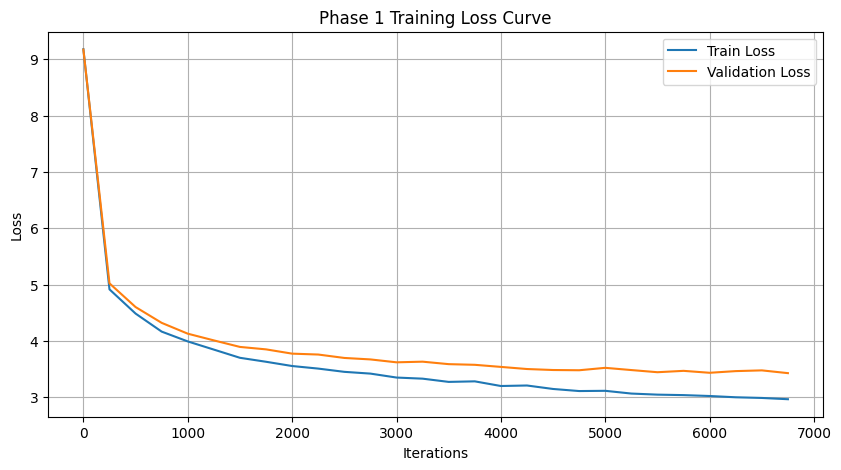

In [59]:
plt.figure(figsize=(10, 5))

plt.plot(iters, train_losses, label="Train Loss")
plt.plot(iters, val_losses, label="Validation Loss")

plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Phase 1 Training Loss Curve")
plt.legend()
plt.grid(True)

plt.show()

## Phase 2 Training (7k-10k)

In [61]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=lr2
)

In [62]:
for param_group in optimizer.param_groups:
    param_group["lr"] = lr2

for iter in range(max_iters1, max_iters2):

    if iter % eval_interval == 0 or iter == max_iters2 - 1:
        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        iters.append(iter)

        print(
            f"Step {iter}: "
            f"Train Loss {losses['train']:.4f}, "
            f"Val Loss {losses['val']:.4f}"
        )

        if losses["val"] < min_val_loss:
            min_val_loss = losses["val"]

            torch.save({
                "iteration": iter,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": min_val_loss
            }, "best_model.pth")

            # print("Saved new best model!")

    x, y = get_batch("train")
    x = x.to(device)
    y = y.to(device)

    logits, loss = model(x, y)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

Step 7000: Train Loss 2.9141, Val Loss 3.4269
Step 7250: Train Loss 2.8977, Val Loss 3.3852
Step 7500: Train Loss 2.9230, Val Loss 3.3955
Step 7750: Train Loss 2.9150, Val Loss 3.3765
Step 8000: Train Loss 2.8703, Val Loss 3.3597
Step 8250: Train Loss 2.8879, Val Loss 3.3828
Step 8500: Train Loss 2.8508, Val Loss 3.3794
Step 8750: Train Loss 2.8439, Val Loss 3.3536
Step 9000: Train Loss 2.8695, Val Loss 3.3639
Step 9250: Train Loss 2.8604, Val Loss 3.3246
Step 9500: Train Loss 2.8442, Val Loss 3.3662
Step 9750: Train Loss 2.8142, Val Loss 3.3513
Step 9999: Train Loss 2.8249, Val Loss 3.3464


# Visualization of Loss Curve

In [63]:
min_val_loss_index= val_losses.index(min(val_losses))
min_val_iter= iters[min_val_loss_index]
min_val_iter

9250

In [64]:
# min_train_loss_index= train_losses.index(min(train_losses))
# min_train_iter= iters[min_train_loss_index]
# min_train_iter

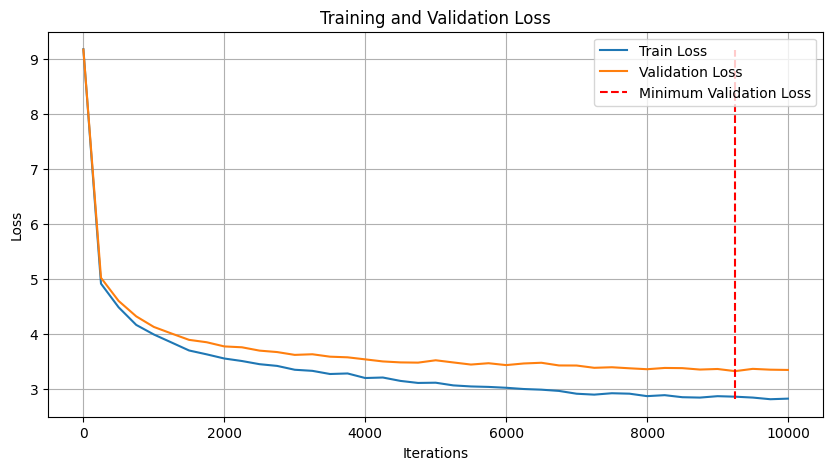

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(iters, train_losses, label="Train Loss")
plt.plot(iters, val_losses, label="Validation Loss")

plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.vlines(x=min_val_iter, ymin=min(train_losses), ymax=max(val_losses), colors='r', linestyles='--', label="Minimum Validation Loss")
# plt.vlines(x=min_train_iter, ymin=min(train_losses), ymax=max(val_losses), colors='g', linestyles='--', label="Minimum Training Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

# Selecting best model

In [66]:
# Load the best saved checkpoint
checkpoint = torch.load("best_model.pth", map_location=device)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Best Model: \n")
print(f"Iteration: {checkpoint['iteration']}")
print(f"Validation Loss: {checkpoint['val_loss']}")

Best Model: 

Iteration: 9250
Validation Loss: 3.3246452808380127


# Inference

In [67]:
model.eval()

LanguageModel(
  (embedding): TokenAndPositionEmbedding(
    (token_embedding): Embedding(8000, 256)
    (position_embedding): Embedding(128, 256)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (blocks): ModuleList(
    (0-3): 4 x TransformerBlock(
      (attention): MultiHeadAttention(
        (heads): ModuleList(
          (0-3): 4 x Head(
            (key): Linear(in_features=256, out_features=64, bias=False)
            (query): Linear(in_features=256, out_features=64, bias=False)
            (value): Linear(in_features=256, out_features=64, bias=False)
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
        (output_projection): Linear(in_features=256, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (feed_forward): FeedForward(
        (network): Sequential(
          (0): Linear(in_features=256, out_features=1024, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=1024, out

In [78]:
prompt= "Hermione and Harry"

# Encode the prompt using your trained tokenizer
encoded_prompt = tokenizer.encode(prompt)
context = torch.tensor(
    [encoded_prompt.ids],
    dtype=torch.long,
    device=device
)

# Generate new tokens
with torch.no_grad():
    generated_ids = model.generate(
        context,
        max_new_tokens=300+len(prompt)
    )

# Decode the generated tokens
output = tokenizer.decode(generated_ids[0].tolist())

print("Input: ",prompt)

print("\nOutput: \n")
print(output)
# model.train()


Input:  Hermione and Harry

Output: 

Hermione and Harry thuffled his hair on the spot at him to what appeared.
“We all have,” he said softly. “Books in. Lown mad lace, I hope Professor
Trelawney, you will borrow it. Those who have a soft quill with a stategy apple as
good as the veela.”
“I’m telling yourselves now,” said Harry.
He was completely laughing, but he wasted for a right change. Perhaps he had a
waicious story?
Harry was standing too.
“Not  it,”  Harry  told  to  Hermione,  and  Hermione  could  not  bear  to
stop  the  owls.  “I’ve  seen  any  strange,”  she  said  brightly,  striding  to  Dumbledore,
skenuss plates. “Who can ’b showed who should have an ‘ecsemprake
sixicial’?”
“I’m  taking  Draco’s  Stone,  to  you,”  said Yaxley  brightly.  “I’ve  been  a  lot
examination, because he didn’t have a job —”
“Not tomorrow, or Hermione keep Ron purpose, but —”
“I need,” said Harry.
“Of course that — they —” She sounded as though she had jumped away from her feet
inside  her  s